# B5 — Analyse de la campagne d'injection de pannes

Ce notebook relit les résultats de `python -m notesfrais campaign` (`results/runs.json`, `results/summary.json`)
et de l'exécution réelle `python -m notesfrais real-run` (`results/real_llm.json`). Il ne relance rien : il est
reproductible sans réseau ni clé.

**Question posée** : un workflow à 5 étapes avec effets externes (virement, e-mail) peut-il subir des crashs
brutaux, des doublons de livraison et des pannes transitoires **sans répéter ses effets** ? On compare :

- **Naïf (baseline)** : même pipeline, mêmes retries, mais ni état d'étape ni clé d'idempotence ; le message n'est
  acquitté qu'en fin de traitement (livraison *at-least-once*) ;
- **Protégé** : étapes persistées dans SQLite (WAL), clés d'idempotence côté services, cache LLM, compensation.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS = Path("..") / "results"
runs = pd.DataFrame(json.loads((RESULTS / "runs.json").read_text(encoding="utf-8")))
summary = json.loads((RESULTS / "summary.json").read_text(encoding="utf-8"))
COLORS = {"naive": "#eb6834", "protected": "#2a78d6"}
LABELS = {"naive": "Naïf (baseline)", "protected": "Protégé"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.grid.axis": "y", "grid.color": "#e4e2dd", "axes.axisbelow": True, "font.size": 11})
print(f"Campagne du {summary['generated_at']} — seeds {summary['seeds']}, {summary['n_requests']} demandes par run")
runs[["mode", "seed", "completion_rate", "duplicate_effects", "inconsistent_requests", "crashes",
      "faults_total", "llm_calls", "duration_s"]]

Campagne du 2026-10-26 17:14:55 — seeds [0, 1, 2, 3, 4], 40 demandes par run


,mode,seed,completion_rate,duplicate_effects,inconsistent_requests,crashes,faults_total,llm_calls,duration_s
0,naive,0,1.0,22,12,9,37,58,11.51
1,naive,1,1.0,16,7,13,38,60,12.72
2,naive,2,1.0,13,7,15,44,64,13.19
3,naive,3,1.0,26,12,14,39,61,13.97
4,naive,4,1.0,17,6,14,43,60,13.40
5,protected,0,1.0,0,0,8,28,42,9.51
6,protected,1,1.0,0,0,9,22,44,9.61
7,protected,2,1.0,0,0,9,32,43,9.78
8,protected,3,1.0,0,0,12,30,41,10.82
9,protected,4,1.0,0,0,11,34,43,10.34


## 1. Volume de pannes injectées

La fiche B5 demande au moins 40 pannes injectées. On compte séparément les **crashs du worker** (kills `psutil`
par le script chaos + points de crash aléatoires `os._exit`) et les autres pannes (erreurs 500 / timeouts des
services, JSON invalide ou indisponibilité du LLM simulé, doublons de livraison).

In [2]:
faults = pd.DataFrame({m: v["faults"] for m, v in summary["by_mode"].items()}).rename(columns=LABELS)
faults.loc["TOTAL"] = faults.sum()
faults

,Naïf (baseline),Protégé
worker_kills,35,24
crash_points,30,25
service_faults,84,54
llm_faults,22,13
duplicate_deliveries,30,30
TOTAL,201,146


## 2. Effets dupliqués

Un effet dupliqué = un virement, un remboursement ou un e-mail exécuté plus d'une fois pour la même demande
(compté dans le registre transactionnel des services, pas dans le journal).

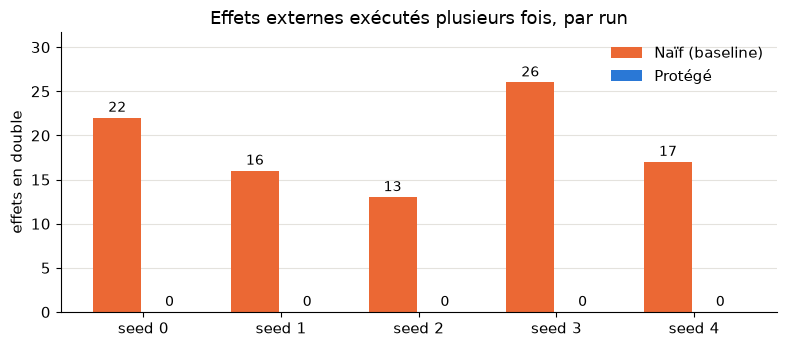

,Naïf (baseline),Protégé
email,44,0
payment,44,0
refund,6,0


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
seeds = sorted(runs.seed.unique())
width = 0.38
for i, mode in enumerate(["naive", "protected"]):
    sub = runs[runs["mode"] == mode].set_index("seed").reindex(seeds)
    xs = [s + (i - 0.5) * width for s in range(len(seeds))]
    bars = ax.bar(xs, sub["duplicate_effects"], width - 0.03, color=COLORS[mode], label=LABELS[mode])
    ax.bar_label(bars, padding=2, fontsize=10)
ax.set_xticks(range(len(seeds)), [f"seed {s}" for s in seeds])
ax.set_ylim(0, runs["duplicate_effects"].max() * 1.18 + 1)
ax.set_ylabel("effets en double")
ax.set_title("Effets externes exécutés plusieurs fois, par run")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

dup_kind = pd.DataFrame({LABELS[m]: runs[runs["mode"] == m]["duplicate_by_kind"].apply(pd.Series).sum()
                         for m in ["naive", "protected"]}).fillna(0).astype(int)
dup_kind

**Lecture.** En mode naïf, chaque crash survenu entre l'effet et l'acquittement fait rejouer la demande
entière, et chaque `timeout_after` (le service a payé mais la réponse est perdue) est réessayé sans clé : d'où des
virements et des e-mails en double. Le mode protégé n'en produit **aucun** : les étapes terminées ne sont pas
rejouées, et les effets rejoués portent la même clé, que le service reconnaît (`idempotent_replays`).

## 3. Cohérence et complétion

In [4]:
cols = ["completion_rate", "duplicate_effects", "requests_with_duplicates", "inconsistent_requests",
        "compensations", "steps_replayed", "idempotent_replays", "llm_calls", "llm_cache_hits"]
pd.DataFrame({LABELS[m]: {c: summary["by_mode"][m][c] for c in cols} for m in ["naive", "protected"]})

,Naïf (baseline),Protégé
completion_rate,1.0,1.0
duplicate_effects,94.0,0.0
requests_with_duplicates,53.0,0.0
inconsistent_requests,44.0,0.0
compensations,13.0,15.0
steps_replayed,278.0,0.0
idempotent_replays,0.0,25.0
llm_calls,303.0,213.0
llm_cache_hits,0.0,2.0


Le taux de complétion est de 100 % dans les deux modes : le mode naïf **finit** bien ses demandes, mais dans un
état faux (effets nets ≠ statut final : double virement pour une note « payée », e-mails contradictoires…).
C'est exactement ce que la complétion seule ne montre pas, d'où la mesure `inconsistent_requests`.

## 4. Temps de reprise après crash

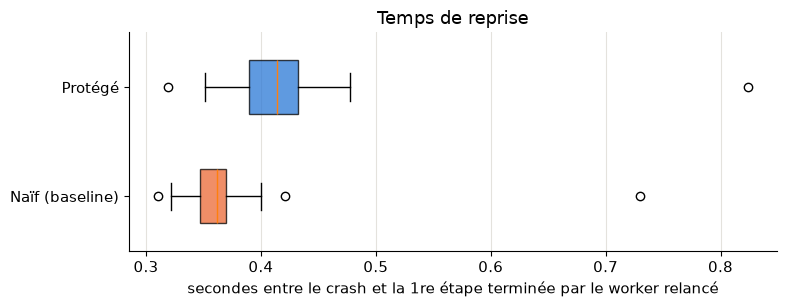

,Naïf (baseline),Protégé
n,65.0000,49.0000
p50 (s),0.3617,0.4139
p95 (s),0.4000,0.4739


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
data = [[x for xs in runs[runs["mode"] == m]["recovery_samples"] for x in xs] for m in ["naive", "protected"]]
bp = ax.boxplot(data, orientation="horizontal", widths=0.5, patch_artist=True, showfliers=True)
for patch, m in zip(bp["boxes"], ["naive", "protected"]):
    patch.set_facecolor(COLORS[m])
    patch.set_alpha(0.75)
ax.set_yticks([1, 2], [LABELS["naive"], LABELS["protected"]])
ax.grid(False)
ax.grid(axis="x")
ax.set_xlabel("secondes entre le crash et la 1re étape terminée par le worker relancé")
ax.set_title("Temps de reprise")
plt.tight_layout()
plt.show()
pd.DataFrame({LABELS[m]: {"n": summary["by_mode"][m]["recovery_n"], "p50 (s)": summary["by_mode"][m]["recovery_p50_s"],
              "p95 (s)": summary["by_mode"][m]["recovery_p95_s"]} for m in ["naive", "protected"]})

**Lecture.** La reprise est dominée par le redémarrage d'un processus Python (~0,3–0,4 s sous Windows).
Le mode protégé est légèrement plus lent à reprendre (lecture de l'état, rejeu idempotent de l'effet en cours),
mais il **ne refait pas** les étapes déjà terminées (`steps_replayed` = 0) alors que le mode naïf les refait
toutes : sur une campagne entière, le mode protégé finit plus vite et appelle moins le LLM.

## 5. Vrai LLM (OpenRouter, Semantic Kernel)

La campagne utilise un LLM simulé déterministe (budget du cours). Le vrai modèle est utilisé sur 10 demandes
variées (français/anglais, 4 devises, refus, compensation), avec un **crash forcé juste après l'appel LLM** : la
reprise doit lire le cache au lieu de rappeler le modèle.

In [6]:
real_path = RESULTS / "real_llm.json"
if real_path.exists():
    real = json.loads(real_path.read_text(encoding="utf-8"))
    display(pd.Series(real["summary"]).to_frame("valeur"))
    display(pd.DataFrame([{"demande": r["request_id"], "scénario": r["scenario"], **r["obtenu"],
                           "correct": all(r["champs_corrects"].values()), "statut": r["statut"]}
                          for r in real["rows"]]))
else:
    print("Pas encore d'exécution réelle.")

,valeur
model,qwen/qwen3.8-flash
requests,10
real_llm_calls,10
llm_cache_hits,1
crashes,1
duplicate_effects,0
statuses,"{'REJECTED': 3, 'DONE': 6, 'COMPENSATED': 1}"
field_accuracy,"{'montant': 1.0, 'devise': 1.0, 'categorie': 1..."
exact_match_rate,1.0
budget_used_total,11


,demande,scénario,montant,devise,categorie,date,motif,correct,statut
0,R001,nominal,34.5,EUR,repas,2026-10-12,Déjeuner client au restaurant,True,DONE
1,R005,nominal,62.4,USD,transport,2026-09-15,Trajet en taxi de l'aéroport JFK au bureau,True,DONE
2,R008,nominal,150.0,GBP,hebergement,2026-09-22,Hôtel à Londres pour atelier partenaire,True,DONE
3,R010,nominal,36.0,CHF,repas,2026-09-30,Dîner avec le partenaire à Genève,True,DONE
4,R017,nominal,41.8,USD,repas,2026-09-16,Déjeuner d'affaires à Boston,True,DONE
5,R021,nominal,146.0,EUR,transport,2026-09-29,Location de voiture pour déplacement à Bordeaux,True,DONE
6,R029,plafond,212.0,EUR,repas,2026-10-09,Dîner de gala avec clients,True,REJECTED
7,R033,date_future,74.0,EUR,transport,2026-11-15,Billet de train pour séminaire,True,REJECTED
8,R034,date_ancienne,27.0,EUR,repas,2026-05-12,Déjeuner d'équipe,True,REJECTED
9,R037,email_invalide,31.2,EUR,repas,2026-10-08,Déjeuner avec un prospect,True,COMPENSATED


## 6. Limites

- Les services externes sont simulés dans une base SQLite séparée : en production, la clé d'idempotence doit être
  supportée par le vrai service (Stripe, API de paiement interne…) — sinon il faut un registre d'effets côté client.
- Un seul worker à la fois : l'extension « plusieurs workers » demanderait un verrou par demande (bail / lease).
- Le temps de reprise mesuré inclut surtout le redémarrage du processus ; il dépend de la machine.
- Le LLM simulé renvoie la vérité terrain : la qualité d'extraction n'est mesurée que sur les 10 appels réels.
- La date de référence des règles est fixe (20/10/2026) pour garder les contrôles déterministes.